download what is needed 

In [2]:
# Install scanpy (single-cell analysis) and pydeseq2 (differential expression).
%pip install -q scanpy pydeseq2


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
# Hide harmless warning messages.
import warnings
warnings.filterwarnings('ignore')

# Packages for numbers, tables and plots.
import numpy
import pandas
import matplotlib.pyplot

# Package for single-cell analysis.
import scanpy

# PyDESeq2: the same tools as in the bulk sessions.
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
from pydeseq2.default_inference import DefaultInference

# Make the plots a bit smaller, with a white background.
scanpy.settings.set_figure_params(dpi=80, figsize=(4, 4), facecolor='white')

# PyDESeq2 will use the 2 processors that Colab gives us.
inference = DefaultInference(n_cpus=2)

In [4]:
# Print the versions we use (write them in your methods).
from importlib.metadata import version

print('scanpy   version:', version('scanpy'))
print('pydeseq2 version:', version('pydeseq2'))
print('anndata  version:', version('anndata'))

scanpy   version: 1.12.4
pydeseq2 version: 0.5.4
anndata  version: 0.13.4


load data 

In [5]:
# Where the file lives on the internet.
url = 'https://exampledata.scverse.org/pertpy/kang_2018.h5ad'

# Download it into a folder called 'data' and read it.
adata = scanpy.read('data/kang_2018.h5ad', backup_url=url)

# Summary: number of cells x number of genes.
print(adata)

AnnData object with n_obs × n_vars = 24673 × 15706
    obs: 'nCount_RNA', 'nFeature_RNA', 'tsne1', 'tsne2', 'label', 'cluster', 'cell_type', 'replicate', 'nCount_SCT', 'nFeature_SCT', 'integrated_snn_res.0.4', 'seurat_clusters'
    var: 'name'
    obsm: 'X_pca', 'X_umap'
    layers: None (.X)


In [6]:
# Which columns describe the cells?
print(list(adata.obs.columns))

['nCount_RNA', 'nFeature_RNA', 'tsne1', 'tsne2', 'label', 'cluster', 'cell_type', 'replicate', 'nCount_SCT', 'nFeature_SCT', 'integrated_snn_res.0.4', 'seurat_clusters']


In [7]:
# The condition (ctrl or stim).
adata.obs['condition'] = adata.obs['label'].astype(str)

# The cell type, as annotated by the authors.
adata.obs['cell_type'] = adata.obs['cell_type'].astype(str)

# The donor. Its column name differs between copies of this dataset,
# so we try the usual names one by one.
for name in ['replicate', 'patient', 'donor', 'ind', 'individual']:
    if name in adata.obs.columns:
        adata.obs['donor'] = adata.obs[name].astype(str)
        print('donor information found in column:', name)
        break

donor information found in column: replicate


In [8]:
# Take the values of the matrix.
# (A sparse matrix stores only its non-zero values, in .data)
if hasattr(adata.X, 'toarray'):
    values = adata.X.data
else:
    values = adata.X

# Raw counts are whole numbers: rounding them changes nothing.
are_counts = numpy.allclose(values, numpy.round(values))
print('the matrix holds raw counts:', are_counts)

# Keep a copy of the raw counts.
adata.layers['counts'] = adata.X.copy()

the matrix holds raw counts: True


Pseudoreplication (the simulation)

In [9]:
def simulate_experiment(cells_per_donor=300, donors_per_group=3, donor_sd=0.3, seed=0):

    # Random number generator (the seed makes results repeatable).
    rng = numpy.random.default_rng(seed)

    n_genes = 1000
    n_true = 50

    # Average expression of each gene (counts per cell).
    gene_mean = rng.gamma(shape=0.6, scale=2.0, size=n_genes)

    # The first 50 genes truly change: True for them, False for the rest.
    truly_changed = numpy.arange(n_genes) < n_true

    all_counts = []
    donor_of_cell = []
    condition_of_cell = []

    for condition in ['ctrl', 'stim']:
        for d in range(donors_per_group):

            donor_name = condition + '_donor' + str(d + 1)

            # This donor differs a little from the average in every gene.
            donor_effect = numpy.exp(rng.normal(0, donor_sd, n_genes))
            donor_mean = gene_mean * donor_effect

            # Treated donors: the 50 true genes go up two-fold.
            if condition == 'stim':
                fold = numpy.where(truly_changed, 2.0, 1.0)
                donor_mean = donor_mean * fold

            # Cells differ in how many molecules were captured.
            library = rng.lognormal(0, 0.3, cells_per_donor)
            expected = library[:, None] * donor_mean[None, :]

            # Draw counts from a negative binomial distribution.
            counts = rng.negative_binomial(5, 5 / (5 + expected))

            all_counts.append(counts)
            donor_of_cell = donor_of_cell + [donor_name] * cells_per_donor
            condition_of_cell = condition_of_cell + [condition] * cells_per_donor

    # Put everything into an AnnData object.
    matrix = numpy.vstack(all_counts).astype('float32')
    data = scanpy.AnnData(X=matrix)
    data.obs['donor'] = donor_of_cell
    data.obs['condition'] = condition_of_cell
    data.var['truly_changed'] = truly_changed
    return data

In [10]:
# Simulate one experiment with the default settings.
simulated = simulate_experiment()

print(simulated)

AnnData object with n_obs × n_vars = 1800 × 1000
    obs: 'donor', 'condition'
    var: 'truly_changed'
    layers: None (.X)


In [11]:
# Check the design: 300 cells per donor, 3 donors per condition.
pandas.crosstab(simulated.obs['donor'], simulated.obs['condition'])

condition,ctrl,stim
donor,,
ctrl_donor1,300,0
ctrl_donor2,300,0
ctrl_donor3,300,0
stim_donor1,0,300
stim_donor2,0,300
stim_donor3,0,300


In [12]:
def pseudobulk_test(data):

    # Table of counts: rows = cells, columns = genes.
    cell_table = pandas.DataFrame(data.X, index=data.obs_names, columns=data.var_names)

    # Sum the cells of each donor: rows = donors, columns = genes.
    donor_table = cell_table.groupby(data.obs['donor'].values).sum()

    # PyDESeq2 wants whole numbers.
    donor_table = donor_table.round().astype(int)

    # Metadata: the condition of each donor.
    donor_condition = data.obs.groupby('donor')['condition'].first()
    metadata = pandas.DataFrame({'condition': donor_condition})
    metadata = metadata.loc[donor_table.index]

    # Fit the negative binomial model, as in the bulk sessions.
    dds = DeseqDataSet(counts=donor_table, metadata=metadata,
                       design='~condition', inference=inference, quiet=True)
    dds.deseq2()

    # Test stim against ctrl.
    stats = DeseqStats(dds, contrast=['condition', 'stim', 'ctrl'],
                       inference=inference, quiet=True)
    stats.summary()

    # Return the adjusted p-values, in the original gene order.
    return stats.results_df['padj'].reindex(data.var_names)

In [13]:
def count_hits(padj, truly_changed):

    # A gene is called significant if its adjusted p-value is below 0.05.
    # Genes without a p-value (NaN) count as not significant.
    significant = (padj < 0.05).fillna(False).values

    # True positives: significant AND truly changed.
    true_positives = (significant & truly_changed).sum()

    # False positives: significant but NOT truly changed.
    false_positives = (significant & ~truly_changed).sum()

    return true_positives, false_positives

In [14]:
def cell_level_test(data):

    # Work on a copy, so the original stays untouched.
    data = data.copy()

    # Normalize and log-transform, as in CW41.
    scanpy.pp.normalize_total(data, target_sum=1e4)
    scanpy.pp.log1p(data)

    # Wilcoxon test: stim cells against ctrl cells.
    scanpy.tl.rank_genes_groups(data, groupby='condition', groups=['stim'],
                                reference='ctrl', method='wilcoxon')

    # Get the results as a table, one row per gene.
    table = scanpy.get.rank_genes_groups_df(data, group='stim')
    table = table.set_index('names')

    # Return the adjusted p-values, in the original gene order.
    return table['pvals_adj'].reindex(data.var_names)

In [15]:
# Which genes truly changed in the simulation?
truth = simulated.var['truly_changed'].values

# Run both tests on the same simulated data.
padj_cells = cell_level_test(simulated)
padj_pseudobulk = pseudobulk_test(simulated)

# Count the hits.
tp_cells, fp_cells = count_hits(padj_cells, truth)
tp_pb, fp_pb = count_hits(padj_pseudobulk, truth)

print('                     true positives (of 50)   false positives (of 950)')
print('cell-level Wilcoxon ', tp_cells, '                     ', fp_cells)
print('pseudobulk PyDESeq2 ', tp_pb, '                     ', fp_pb)

                     true positives (of 50)   false positives (of 950)
cell-level Wilcoxon  41                       368
pseudobulk PyDESeq2  15                       2


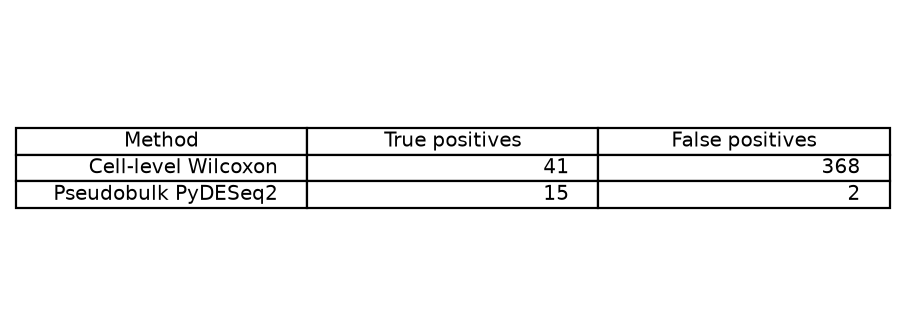

In [21]:
simulation_results = pandas.DataFrame({
    'Method': ['Cell-level Wilcoxon', 'Pseudobulk PyDESeq2'],
    'True positives': [tp_cells, tp_pb],
    'False positives': [fp_cells, fp_pb]
})

simulation_results

from pathlib import Path

Path("results/module3").mkdir(parents=True, exist_ok=True)

fig, ax = matplotlib.pyplot.subplots(figsize=(7, 2.5))
ax.axis("off")
ax.table(
    cellText=simulation_results.values,
    colLabels=simulation_results.columns,
    loc="center"
)

matplotlib.pyplot.savefig(
    "results/module3/pseudoreplication_true_false_positives.png",
    dpi=300,
    bbox_inches="tight"
)

matplotlib.pyplot.show()
matplotlib.pyplot.close()

Pseudoreplication on real data 

In [16]:
# Sum the raw counts for every donor x condition x cell type.
pseudobulk = scanpy.get.aggregate(adata,
                                  by=['donor', 'condition', 'cell_type'],
                                  func='sum',
                                  layer='counts')

# Summary: number of pseudobulk samples x number of genes.
print(pseudobulk)

AnnData object with n_obs × n_vars = 124 × 15706
    obs: 'donor', 'condition', 'cell_type', 'n_obs_aggregated'
    var: 'name'
    layers: 'sum'


In [23]:
# How many cells went into each pseudobulk sample?
cells_per_sample = adata.obs.groupby(['donor', 'condition', 'cell_type']).size()
cells_per_sample = cells_per_sample.rename('n_cells')

# Add this number to the pseudobulk table.
pseudobulk.obs = pseudobulk.obs.join(cells_per_sample, on=['donor', 'condition', 'cell_type'])

pseudobulk.obs.head(10)

,donor,condition,cell_type,n_obs_aggregated,n_cells
patient_101_ctrl_B cells,patient_101,ctrl,B cells,106,106
patient_101_ctrl_CD14+ Monocytes,patient_101,ctrl,CD14+ Monocytes,207,207
patient_101_ctrl_CD4 T cells,patient_101,ctrl,CD4 T cells,353,353
patient_101_ctrl_CD8 T cells,patient_101,ctrl,CD8 T cells,29,29
patient_101_ctrl_Dendritic cells,patient_101,ctrl,Dendritic cells,25,25
patient_101_ctrl_FCGR3A+ Monocytes,patient_101,ctrl,FCGR3A+ Monocytes,72,72
patient_101_ctrl_Megakaryocytes,patient_101,ctrl,Megakaryocytes,1,1
patient_101_ctrl_NK cells,patient_101,ctrl,NK cells,65,65
patient_101_stim_B cells,patient_101,stim,B cells,141,141
patient_101_stim_CD14+ Monocytes,patient_101,stim,CD14+ Monocytes,269,269


In [17]:
# All cell type names in the data.
cell_types = sorted(adata.obs['cell_type'].unique())
print(cell_types)

# Pick the one whose name contains 'CD14'.
focus = None
for name in cell_types:
    if 'CD14' in name:
        focus = name

print('cell type analysed:', focus)

['B cells', 'CD14+ Monocytes', 'CD4 T cells', 'CD8 T cells', 'Dendritic cells', 'FCGR3A+ Monocytes', 'Megakaryocytes', 'NK cells']
cell type analysed: CD14+ Monocytes


In [24]:
# Keep the pseudobulk samples of this cell type.
selected = pseudobulk[pseudobulk.obs['cell_type'] == focus]

# Drop samples built from fewer than 10 cells (too noisy).
selected = selected[selected.obs['n_cells'] >= 10]

print('pseudobulk samples kept:', selected.n_obs)

pseudobulk samples kept: 16


In [25]:
# Count table: rows = samples, columns = genes.
counts = pandas.DataFrame(selected.layers['sum'],
                          index=selected.obs_names,
                          columns=selected.var_names)

# PyDESeq2 wants whole numbers.
counts = counts.round().astype(int)

# Remove genes with almost no counts (fewer than 10 in total).
total_per_gene = counts.sum(axis=0)
counts = counts.loc[:, total_per_gene >= 10]

print('samples:', counts.shape[0], '   genes kept:', counts.shape[1])

samples: 16    genes kept: 10086


In [26]:
# Metadata table: the donor and condition of every sample.
metadata = pandas.DataFrame(index=selected.obs_names)
metadata['donor'] = selected.obs['donor'].astype(str)
metadata['condition'] = selected.obs['condition'].astype(str)
metadata['n_cells'] = selected.obs['n_cells']

metadata

,donor,condition,n_cells
patient_101_ctrl_CD14+ Monocytes,patient_101,ctrl,207
patient_101_stim_CD14+ Monocytes,patient_101,stim,269
patient_1015_ctrl_CD14+ Monocytes,patient_1015,ctrl,859
patient_1015_stim_CD14+ Monocytes,patient_1015,stim,718
patient_1016_ctrl_CD14+ Monocytes,patient_1016,ctrl,393
patient_1016_stim_CD14+ Monocytes,patient_1016,stim,355
patient_1039_ctrl_CD14+ Monocytes,patient_1039,ctrl,126
patient_1039_stim_CD14+ Monocytes,patient_1039,stim,164
patient_107_ctrl_CD14+ Monocytes,patient_107,ctrl,210
patient_107_stim_CD14+ Monocytes,patient_107,stim,179


In [27]:
# Create the PyDESeq2 dataset with the paired design.
dds = DeseqDataSet(counts=counts,
                   metadata=metadata,
                   design='~donor + condition',
                   inference=inference,
                   quiet=True)

# Fit the negative binomial model (size factors, dispersions, fold changes).
dds.deseq2()

In [28]:
# Test stim against ctrl.
stats = DeseqStats(dds,
                   contrast=['condition', 'stim', 'ctrl'],
                   inference=inference,
                   quiet=True)
stats.summary()

# The results table, sorted by adjusted p-value.
results = stats.results_df.sort_values('padj')

# How many genes are significant?
n_significant = (results['padj'] < 0.05).sum()
print('genes with padj < 0.05:', n_significant, 'of', len(results))

genes with padj < 0.05: 3411 of 10086


In [35]:
# The 10 most significant genes.
genes_10 = results.head(10).round(4)

from pandas.plotting import table
import matplotlib.pyplot as plt

fig, ax = plt.subplots()
ax.axis('off')
table(ax, genes_10 , loc='center')

fig.savefig("results/module3/CD14_top10_genes.png", dpi=300, bbox_inches='tight')
plt.close(fig)